
# NYC Taxi Trip Duration — Analyse exploratoire

## 1. Présentation du projet

L'objectif de ce projet est de développer un modèle de Machine Learning capable de prédire la durée des trajets en taxi à New York, à partir des caractéristiques disponibles au moment de la prise en charge.

Ce travail s'appuie sur la compétition Kaggle *NYC Taxi Trip Duration*.

La variable cible est `trip_duration`, exprimée en secondes. Les performances des modèles seront évaluées à l'aide de la métrique RMSLE (Root Mean Squared Logarithmic Error).

## 2. Objectifs de l'analyse exploratoire

Cette première phase vise à :

- Découvrir la structure et les caractéristiques des jeux de données.
- Étudier les distributions statistiques des variables.
- Identifier les valeurs manquantes, incohérentes ou aberrantes.
- Analyser les relations entre les différentes variables.
- Identifier les transformations et traitements nécessaires avant la modélisation.

## 3. Jeux de données

Trois fichiers sont mis à disposition :

- `train.csv` : données d'entraînement, contenant la variable cible.
- `test.csv` : données de test, utilisées pour produire les prédictions.
- `sample_submission.csv` : exemple du format attendu pour les soumissions Kaggle.


In [1]:

# 1. Importation des bibliothèques

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Configuration de l'affichage
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")

# Configuration des graphiques
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 6)

print("Bibliothèques importées avec succès.")
print(f"Version de NumPy : {np.__version__}")
print(f"Version de Pandas : {pd.__version__}")

Bibliothèques importées avec succès.
Version de NumPy : 2.5.4
Version de Pandas : 3.1.0


In [2]:

# 2. Définition des chemins des fichiers

DATA_DIR = Path("../data/raw")

TRAIN_PATH = DATA_DIR / "train.csv"
TEST_PATH = DATA_DIR / "test.csv"
SUBMISSION_PATH = DATA_DIR / "sample_submission.csv"

# Vérification de l'existence des fichiers
files = {
    "Entraînement": TRAIN_PATH,
    "Test": TEST_PATH,
    "Exemple de soumission": SUBMISSION_PATH
}

for name, path in files.items():
    if path.exists():
        print(f"{name} : fichier trouvé ({path})")
    else:
        print(f"{name} : fichier introuvable ({path})")


Entraînement : fichier trouvé (..\data\raw\train.csv)
Test : fichier trouvé (..\data\raw\test.csv)
Exemple de soumission : fichier trouvé (..\data\raw\sample_submission.csv)


In [3]:

# 3. Chargement des jeux de données

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)
submission_df = pd.read_csv(SUBMISSION_PATH)

print("Les trois fichiers ont été chargés avec succès.")

Les trois fichiers ont été chargés avec succès.


In [4]:

# 4. Dimensions des jeux de données

print("Dimensions des jeux de données :\n")

print(f"Entraînement : {train_df.shape[0]:,} lignes et {train_df.shape[1]} colonnes")
print(f"Test         : {test_df.shape[0]:,} lignes et {test_df.shape[1]} colonnes")
print(f"Soumission   : {submission_df.shape[0]:,} lignes et {submission_df.shape[1]} colonnes")


Dimensions des jeux de données :

Entraînement : 1,458,644 lignes et 11 colonnes
Test         : 625,134 lignes et 9 colonnes
Soumission   : 625,134 lignes et 2 colonnes


In [5]:

# 5. Découverte des variables

print("Variables du jeu d'entraînement :")
print(train_df.columns.tolist())

print("\nVariables du jeu de test :")
print(test_df.columns.tolist())

print("\nColonnes du fichier de soumission :")
print(submission_df.columns.tolist())


Variables du jeu d'entraînement :
['id', 'vendor_id', 'pickup_datetime', 'dropoff_datetime', 'passenger_count', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'store_and_fwd_flag', 'trip_duration']

Variables du jeu de test :
['id', 'vendor_id', 'pickup_datetime', 'passenger_count', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'store_and_fwd_flag']

Colonnes du fichier de soumission :
['id', 'trip_duration']



## 4. Description des variables

Les données contiennent des informations relatives aux prestataires, aux horaires, aux passagers et à la localisation géographique des trajets.

| Variable | Description | Nature |
|---|---|---|
| `id` | Identifiant unique du trajet | Identifiant |
| `vendor_id` | Identifiant du prestataire de taxi | Catégorielle |
| `pickup_datetime` | Date et heure de prise en charge | Temporelle |
| `dropoff_datetime` | Date et heure de dépose | Temporelle |
| `passenger_count` | Nombre de passagers | Numérique discrète |
| `pickup_longitude` | Longitude du point de départ | Géographique |
| `pickup_latitude` | Latitude du point de départ | Géographique |
| `dropoff_longitude` | Longitude du point d'arrivée | Géographique |
| `dropoff_latitude` | Latitude du point d'arrivée | Géographique |
| `store_and_fwd_flag` | Indique si les données du trajet ont été stockées avant transmission | Catégorielle binaire |
| `trip_duration` | Durée réelle du trajet en secondes | Variable cible |

La variable `trip_duration` constitue la variable à prédire.

La variable `dropoff_datetime`, disponible uniquement dans le jeu d'entraînement, ne sera pas utilisée comme variable explicative puisqu'elle n'est pas disponible au moment de la prédiction.


In [6]:

# 6. Types de données des variables

print("Types des variables du jeu d'entraînement :\n")
print(train_df.dtypes)

print("\nTypes des variables du jeu de test :\n")
print(test_df.dtypes)


Types des variables du jeu d'entraînement :

id                        str
vendor_id               int64
pickup_datetime           str
dropoff_datetime          str
passenger_count         int64
pickup_longitude      float64
pickup_latitude       float64
dropoff_longitude     float64
dropoff_latitude      float64
store_and_fwd_flag        str
trip_duration           int64
dtype: object

Types des variables du jeu de test :

id                        str
vendor_id               int64
pickup_datetime           str
passenger_count         int64
pickup_longitude      float64
pickup_latitude       float64
dropoff_longitude     float64
dropoff_latitude      float64
store_and_fwd_flag        str
dtype: object


In [7]:

# 7. Analyse des valeurs manquantes

print("Valeurs manquantes dans le jeu d'entraînement :")
print(train_df.isnull().sum())

print("\nValeurs manquantes dans le jeu de test :")
print(test_df.isnull().sum())


Valeurs manquantes dans le jeu d'entraînement :
id                    0
vendor_id             0
pickup_datetime       0
dropoff_datetime      0
passenger_count       0
pickup_longitude      0
pickup_latitude       0
dropoff_longitude     0
dropoff_latitude      0
store_and_fwd_flag    0
trip_duration         0
dtype: int64

Valeurs manquantes dans le jeu de test :
id                    0
vendor_id             0
pickup_datetime       0
passenger_count       0
pickup_longitude      0
pickup_latitude       0
dropoff_longitude     0
dropoff_latitude      0
store_and_fwd_flag    0
dtype: int64


In [8]:

# 8. Analyse des doublons

print("Doublons dans le jeu d'entraînement :")
print(f"Nombre de lignes dupliquées : {train_df.duplicated().sum()}")

print("\nDoublons dans le jeu de test :")
print(f"Nombre de lignes dupliquées : {test_df.duplicated().sum()}")

print("\nDoublons sur les identifiants :")
print(f"Train : {train_df['id'].duplicated().sum()}")
print(f"Test  : {test_df['id'].duplicated().sum()}")


Doublons dans le jeu d'entraînement :
Nombre de lignes dupliquées : 0

Doublons dans le jeu de test :
Nombre de lignes dupliquées : 0

Doublons sur les identifiants :
Train : 0
Test  : 0


In [9]:

# 9. Statistiques descriptives des variables numériques

train_df.describe()


,vendor_id,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,trip_duration
count,1458644.000,1458644.000,1458644.000,1458644.000,1458644.000,1458644.000,1458644.000
mean,1.535,1.665,-73.973,40.751,-73.973,40.752,959.492
std,0.499,1.314,0.071,0.033,0.071,0.036,5237.432
min,1.000,0.000,-121.933,34.360,-121.933,32.181,1.000
25%,1.000,1.000,-73.992,40.737,-73.991,40.736,397.000
50%,2.000,1.000,-73.982,40.754,-73.980,40.755,662.000
75%,2.000,2.000,-73.967,40.768,-73.963,40.770,1075.000
max,2.000,9.000,-61.336,51.881,-61.336,43.921,3526282.000


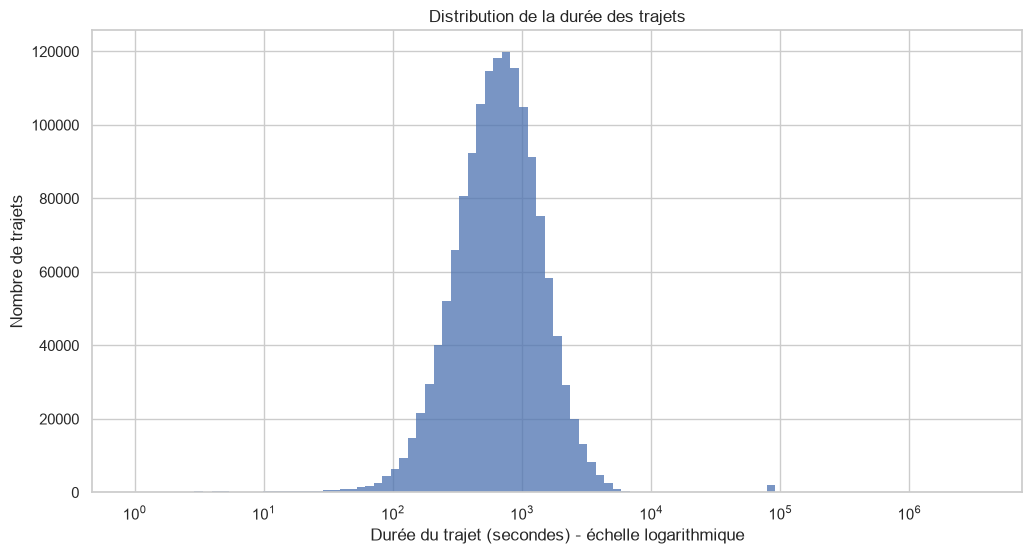

In [11]:


# 10. Distribution de la durée des trajets

# Création de classes à intervalles logarithmiques
bins = np.logspace(
    np.log10(train_df["trip_duration"].min()),
    np.log10(train_df["trip_duration"].max()),
    100
)

plt.figure(figsize=(12, 6))

sns.histplot(
    data=train_df,
    x="trip_duration",
    bins=bins
)

plt.xscale("log")
plt.title("Distribution de la durée des trajets")
plt.xlabel("Durée du trajet (secondes) - échelle logarithmique")
plt.ylabel("Nombre de trajets")

plt.show()



In [12]:

# 11. Quantiles de la durée des trajets

quantiles = train_df["trip_duration"].quantile([
    0.50,
    0.75,
    0.90,
    0.95,
    0.99,
    0.995,
    0.999
])

print("Quantiles de trip_duration :\n")
print(quantiles)

print("\nNombre de trajets dépassant 24 heures :")
print((train_df["trip_duration"] > 86400).sum())


Quantiles de trip_duration :

0.500     662.000
0.750    1075.000
0.900    1634.000
0.950    2104.000
0.990    3440.000
0.995    4139.000
0.999   85128.357
Name: trip_duration, dtype: float64

Nombre de trajets dépassant 24 heures :
4


In [13]:

# 12. Analyse des durées extrêmes

seuils = {
    "Plus d'une heure": 3600,
    "Plus de deux heures": 7200,
    "Plus de six heures": 21600,
    "Plus de douze heures": 43200,
    "Plus de vingt heures": 72000,
    "Plus de vingt-quatre heures": 86400
}

print("Nombre de trajets dépassant différents seuils :\n")

for label, seuil in seuils.items():
    nombre = (train_df["trip_duration"] > seuil).sum()
    pourcentage = nombre / len(train_df) * 100

    print(f"{label:25} : {nombre:6,} ({pourcentage:.4f} %)")

print("\nLes 15 trajets les plus longs :")

print(
    train_df.nlargest(15, "trip_duration")[
        ["id", "pickup_datetime", "dropoff_datetime", "trip_duration"]
    ].to_string(index=False)
)


Nombre de trajets dépassant différents seuils :

Plus d'une heure          : 12,317 (0.8444 %)
Plus de deux heures       :  2,253 (0.1545 %)
Plus de six heures        :  2,061 (0.1413 %)
Plus de douze heures      :  1,993 (0.1366 %)
Plus de vingt heures      :  1,933 (0.1325 %)
Plus de vingt-quatre heures :      4 (0.0003 %)

Les 15 trajets les plus longs :
       id     pickup_datetime    dropoff_datetime  trip_duration
id0053347 2016-02-13 22:46:52 2016-03-25 18:18:14        3526282
id1325766 2016-01-05 06:14:15 2016-01-31 01:01:07        2227612
id0369307 2016-02-13 22:38:00 2016-03-08 15:57:38        2049578
id1864733 2016-01-05 00:19:42 2016-01-27 11:08:38        1939736
id1942836 2016-02-15 23:18:06 2016-02-16 23:17:58          86392
id0593332 2016-05-31 13:00:39 2016-06-01 13:00:30          86391
id0953667 2016-05-06 00:00:10 2016-05-07 00:00:00          86390
id2837671 2016-06-30 16:37:52 2016-07-01 16:37:39          86387
id1358458 2016-06-23 16:01:45 2016-06-24 16:01:30      

Nombre de trajets entre 20 h et 24 h : 1,929

Statistiques descriptives :
count    1929.000
mean    85348.093
std      1586.851
min     72504.000
25%     85162.000
50%     85921.000
75%     86226.000
max     86392.000
Name: trip_duration, dtype: float64

Répartition des durées autour de 24 heures :


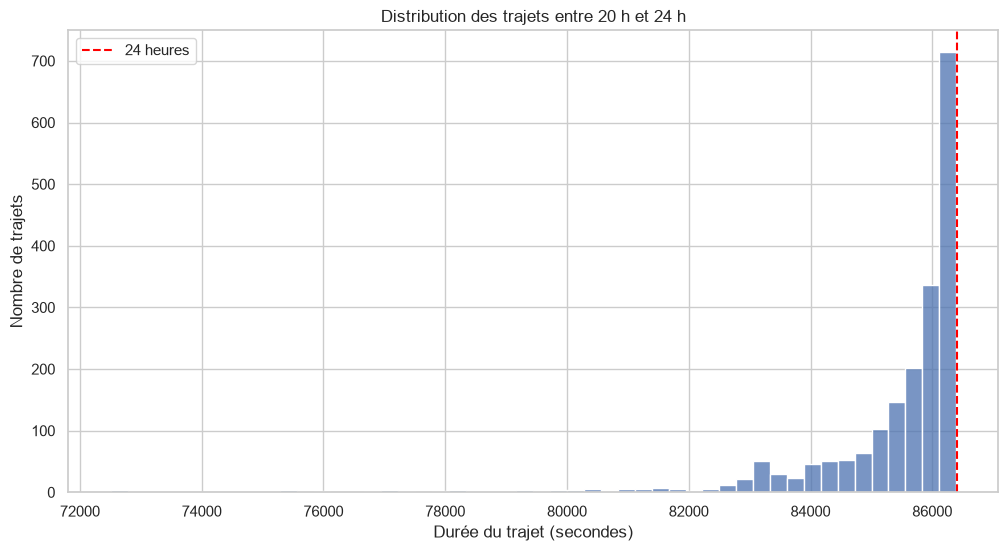

In [14]:

# 13. Analyse des trajets proches de 24 heures

# Sélection analytique uniquement : aucune modification du dataset
long_trips = train_df[
    (train_df["trip_duration"] >= 20 * 3600) &
    (train_df["trip_duration"] < 24 * 3600)
]

print(f"Nombre de trajets entre 20 h et 24 h : {len(long_trips):,}")

print("\nStatistiques descriptives :")
print(long_trips["trip_duration"].describe())

print("\nRépartition des durées autour de 24 heures :")

plt.figure(figsize=(12, 6))

sns.histplot(
    data=long_trips,
    x="trip_duration",
    bins=50
)

plt.axvline(
    86400,
    color="red",
    linestyle="--",
    label="24 heures"
)

plt.title("Distribution des trajets entre 20 h et 24 h")
plt.xlabel("Durée du trajet (secondes)")
plt.ylabel("Nombre de trajets")
plt.legend()

plt.show()


Répartition du nombre de passagers :

                 Nombre de trajets  Pourcentage (%)
passenger_count                                    
0                               60            0.004
1                          1033540           70.856
2                           210318           14.419
3                            59896            4.106
4                            28404            1.947
5                            78088            5.353
6                            48333            3.314
7                                3            0.000
8                                1            0.000
9                                1            0.000


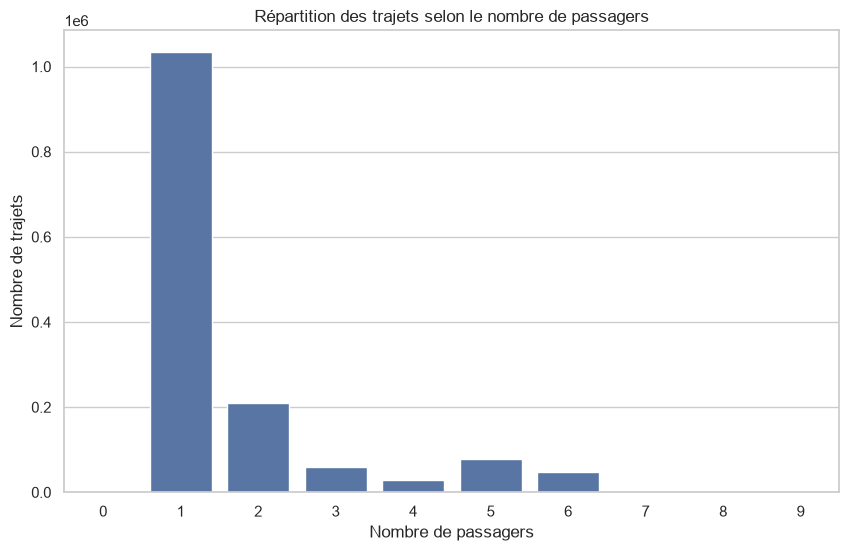

In [15]:

# 14. Distribution du nombre de passagers

passenger_counts = train_df["passenger_count"].value_counts().sort_index()

print("Répartition du nombre de passagers :\n")

print(
    pd.DataFrame({
        "Nombre de trajets": passenger_counts,
        "Pourcentage (%)": passenger_counts / len(train_df) * 100
    }).round(3)
)

plt.figure(figsize=(10, 6))

sns.countplot(
    data=train_df,
    x="passenger_count"
)

plt.title("Répartition des trajets selon le nombre de passagers")
plt.xlabel("Nombre de passagers")
plt.ylabel("Nombre de trajets")

plt.show()


Répartition des prestataires :

           Nombre de trajets  Pourcentage (%)
vendor_id                                    
1                     678342           46.505
2                     780302           53.495


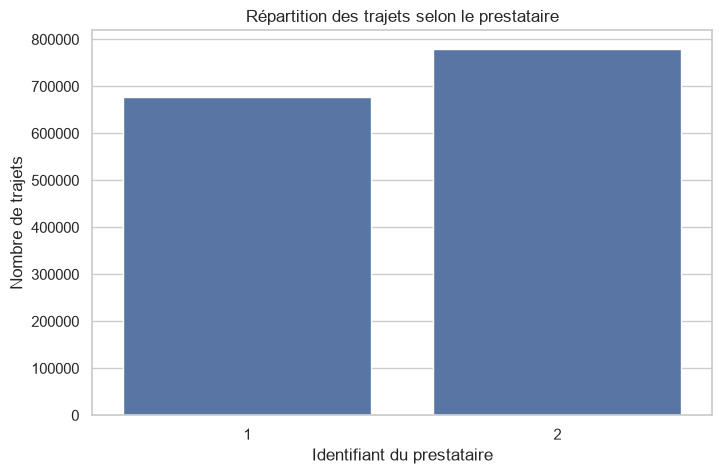

In [19]:

# 15. Répartition des trajets selon le prestataire

vendor_counts = train_df["vendor_id"].value_counts().sort_index()

vendor_stats = pd.DataFrame({
    "Nombre de trajets": vendor_counts,
    "Pourcentage (%)": vendor_counts / len(train_df) * 100
})

print("Répartition des prestataires :\n")
print(vendor_stats.round(3))

plt.figure(figsize=(8, 5))

sns.countplot(
    data=train_df,
    x="vendor_id"
)

plt.title("Répartition des trajets selon le prestataire")
plt.xlabel("Identifiant du prestataire")
plt.ylabel("Nombre de trajets")

plt.show()


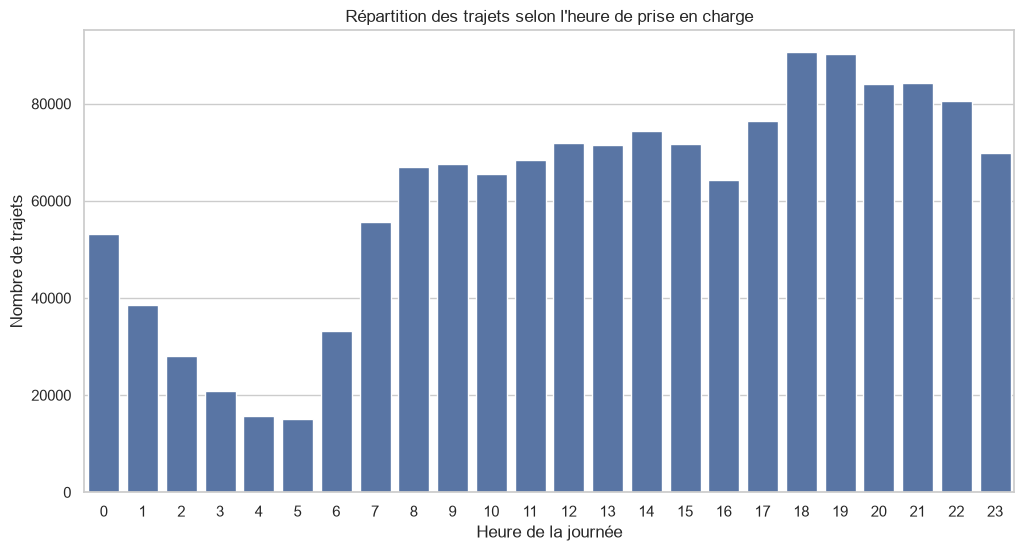

Nombre de trajets par jour :
Lundi       187418
Mardi       202749
Mercredi    210136
Jeudi       218574
Vendredi    223533
Samedi      220868
Dimanche    195366
Name: count, dtype: int64


C:\Users\rayou\AppData\Local\Temp\ipykernel_13068\1838145414.py:31: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  pickup_dates.dt.dayofweek


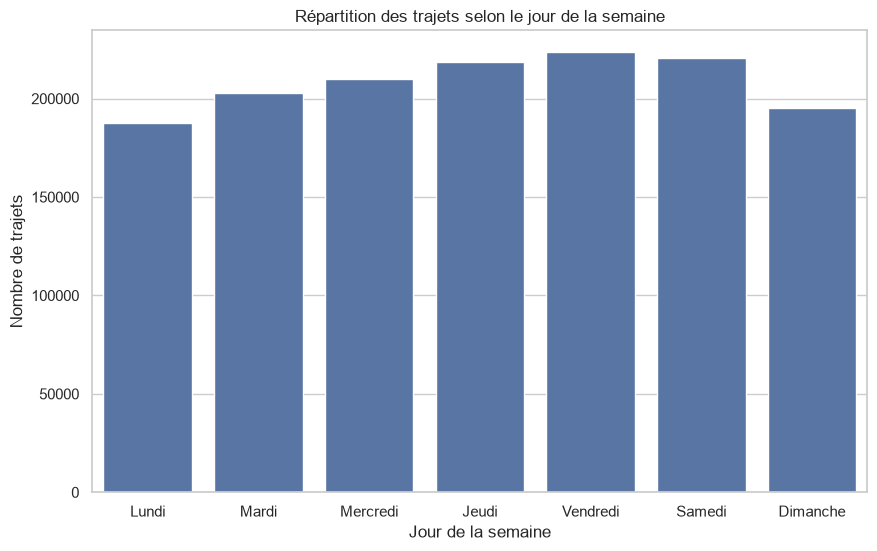

In [20]:

# 17. Répartition des trajets selon l'heure de prise en charge

# Conversion temporaire pour les besoins de l'analyse
pickup_dates = pd.to_datetime(train_df["pickup_datetime"])

trips_by_hour = pickup_dates.dt.hour.value_counts().sort_index()

plt.figure(figsize=(12, 6))

sns.barplot(
    x=trips_by_hour.index,
    y=trips_by_hour.values
)

plt.title("Répartition des trajets selon l'heure de prise en charge")
plt.xlabel("Heure de la journée")
plt.ylabel("Nombre de trajets")
plt.xticks(range(24))

plt.show()


# 18. Répartition des trajets selon le jour de la semaine

jours = [
    "Lundi", "Mardi", "Mercredi", "Jeudi",
    "Vendredi", "Samedi", "Dimanche"
]

trips_by_day = (
    pickup_dates.dt.dayofweek
    .value_counts()
    .reindex(range(7), fill_value=0)
)

trips_by_day.index = jours

print("Nombre de trajets par jour :")
print(trips_by_day)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=trips_by_day.index,
    y=trips_by_day.values
)

plt.title("Répartition des trajets selon le jour de la semaine")
plt.xlabel("Jour de la semaine")
plt.ylabel("Nombre de trajets")

plt.show()


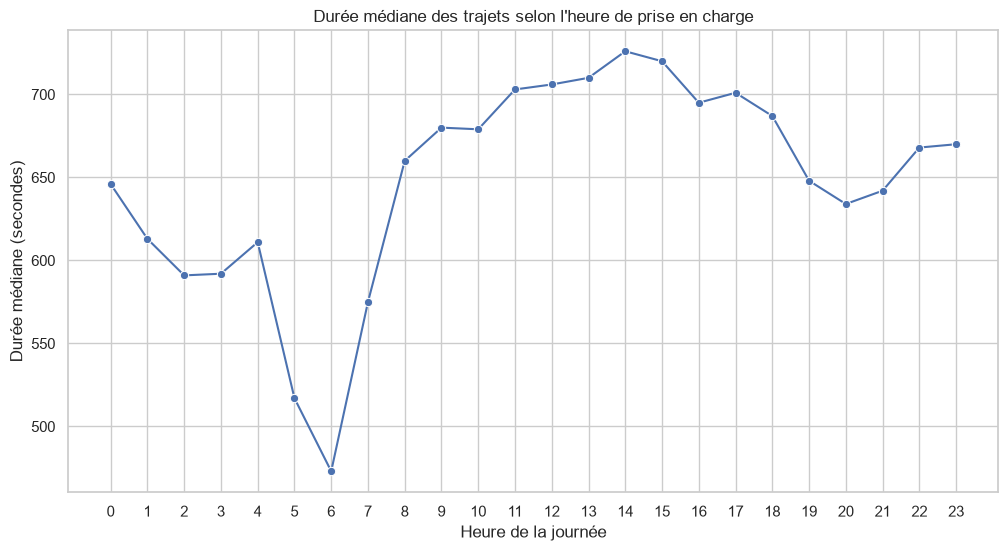

In [21]:

# 19. Durée médiane des trajets selon l'heure

hour_duration = (
    train_df.assign(hour=pickup_dates.dt.hour)
    .groupby("hour")["trip_duration"]
    .median()
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    x=hour_duration.index,
    y=hour_duration.values,
    marker="o"
)

plt.title("Durée médiane des trajets selon l'heure de prise en charge")
plt.xlabel("Heure de la journée")
plt.ylabel("Durée médiane (secondes)")
plt.xticks(range(24))
plt.grid(True)

plt.show()
